# Profit Diagnostic · 02 · Where profit is made, why it changed, where it leaks, what to do
**Client brief (fictional):** *"Our sales grew this year but profit didn't. Where do we make money, where do we lose it, why did margin change, and what should we change in pricing and discounting?"*

Comparison: **P0 = Dec 2011–Nov 2012** vs **P1 = Dec 2012–Nov 2013**. Profit = gross profit (net sales − standard cost). Every number here is reproduced by the SQL scripts in `06_SQL`.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pd_data as pdd          # loading + core calculations (same logic as the SQL scripts)
import pd_charts as ch         # chart style

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)
FIG = Path("../14_Final_Report/figures"); FIG.mkdir(parents=True, exist_ok=True)

# Where the data comes from:
#   "sqlserver" -> dbo.vw_pd_sales_line in AdventureWorksDW2022 (run 06_SQL/00_setup_views.sql first)
#   "csv"       -> Microsoft's CSV install package, unzipped into 03_Raw_Data/
SOURCE = os.getenv("PD_SOURCE", "sqlserver")
SERVER = os.getenv("PD_SERVER", "localhost")      # e.g. "localhost\\SQLEXPRESS"
df = pdd.load_sales_lines(source=SOURCE, server=SERVER)
p1 = df[df["period"] == "P1"]
print(f"Loaded {len(df):,} order lines from {SOURCE}; net sales {df.net_sales.sum():,.2f}")

Loaded 60,855 order lines from csv; net sales 80,450,596.98


## Q1 · Where is profit made?

In [2]:
cat = pdd.summarise(df[df.period.notna()], ["category", "period"])[["net_sales", "gross_profit", "gross_margin_pct"]]
cat

net_sales  gross_profit  gross_margin_pct
category    period                                              
Accessories P0        124,433.35     36,370.91             29.23
            P1        410,049.73    144,557.57             35.25
Bikes       P0     22,417,419.69    366,985.19              1.64
            P1     28,866,427.79 -1,232,916.41             -4.27
Clothing    P0        750,716.33    176,133.88             23.46
            P1        960,796.98     59,986.81              6.24
Components  P0      4,629,101.14    573,954.79             12.40
            P1      6,003,210.20    354,644.91              5.91

In [3]:
models = pdd.summarise(p1, ["category", "model"]).sort_values("gross_profit")
print("Worst 8 models (P1)"); display(models.head(8)[["net_sales", "gross_profit", "gross_margin_pct"]])
print("Best 5 models (P1)");  display(models.tail(5)[["net_sales", "gross_profit", "gross_margin_pct"]])

Worst 8 models (P1)


net_sales  gross_profit  \
category model                                                    
Bikes    Touring-1000                6,723,794.29   -829,643.19   
         Touring-3000                2,046,508.26   -338,699.91   
         Road-350-W                  3,665,932.31   -285,229.19   
         Road-250                    3,214,110.62   -195,890.12   
         Road-550-W                  1,829,947.52   -113,194.94   
Clothing Short-Sleeve Classic Jersey   235,030.25    -75,847.41   
Bikes    Touring-2000                1,681,187.67    -69,251.89   
         Road-750                      966,079.59    -64,525.56   

                                      gross_margin_pct  
category model                                          
Bikes    Touring-1000                           -12.34  
         Touring-3000                           -16.55  
         Road-350-W                              -7.78  
         Road-250                                -6.09  
         Road-550-W                              -6.19  
Clothing Short-Sleeve Classic Jersey            -32.27  
Bikes    Touring-2000                            -4.12  
         Road-750                                -6.68

Best 5 models (P1)


net_sales  gross_profit  \
category    model                                                
Accessories Hitch Rack - 4-Bike       197,736.16     70,366.72   
Clothing    Classic Vest              223,801.37     77,127.55   
            Women's Mountain Shorts   260,304.09     85,969.93   
Components  HL Mountain Frame       1,368,209.88    119,057.42   
Bikes       Mountain-200            7,079,090.17    607,775.99   

                                     gross_margin_pct  
category    model                                      
Accessories Hitch Rack - 4-Bike                 35.59  
Clothing    Classic Vest                        34.46  
            Women's Mountain Shorts             33.03  
Components  HL Mountain Frame                    8.70  
Bikes       Mountain-200                         8.59

In [4]:
# ABC on gross profit (SKU level). Loss-makers are their own class so the cumulative share stays ≤ 100%.
sku = pdd.summarise(p1, "sku").sort_values("gross_profit", ascending=False)
pos = sku.gross_profit.clip(lower=0)
sku["cum_share"] = pos.cumsum() / pos.sum()
sku["abc"] = np.select([sku.gross_profit < 0, sku.cum_share <= .80, sku.cum_share <= .95], ["Loss-making", "A", "B"], "C")
abc = sku.groupby("abc").agg(skus=("lines", "size"), net_sales=("net_sales", "sum"), gross_profit=("gross_profit", "sum"))
abc["share_of_sales_pct"] = abc.net_sales / abc.net_sales.sum() * 100
abc.loc[["A", "B", "C", "Loss-making"]]

,skus,net_sales,gross_profit,share_of_sales_pct
abc,,,,
A,26,"9,989,743.05","1,127,151.58",27.57
B,26,"1,755,739.35","215,023.19",4.84
C,44,"749,659.43","73,411.29",2.07
Loss-making,71,"23,745,342.87","-2,089,313.18",65.52


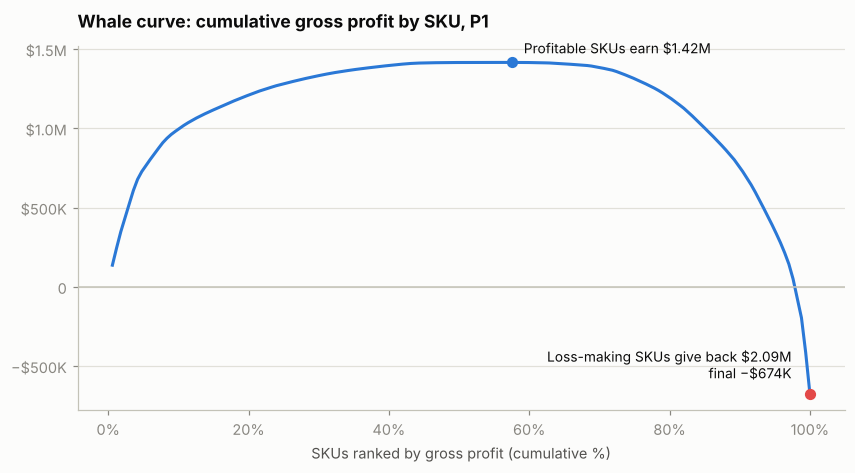

In [5]:
curve = sku.gross_profit.cumsum().reset_index(drop=True)
x = np.arange(1, len(curve) + 1) / len(curve) * 100
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(x, curve.values, color=ch.GAIN, lw=2)
ax.axhline(0, color=ch.AXIS, lw=1)
peak_i = curve.values.argmax()
ax.scatter([x[peak_i]], [curve.max()], s=40, color=ch.GAIN, zorder=3)
ax.annotate(f"Profitable SKUs earn {ch.money(curve.max())}", (x[peak_i], curve.max()), xytext=(8, 6),
            textcoords="offset points", fontsize=9, color=ch.INK)
ax.scatter([100], [curve.iloc[-1]], s=40, color=ch.LOSS, zorder=3)
ax.annotate(f"Loss-making SKUs give back {ch.money(curve.max() - curve.iloc[-1])}\nfinal {ch.money(curve.iloc[-1])}",
            (100, curve.iloc[-1]), xytext=(-12, 10), textcoords="offset points", ha="right", fontsize=9, color=ch.INK)
ax.set_xlabel("SKUs ranked by gross profit (cumulative %)"); ch._money_axis(ax)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title("Whale curve: cumulative gross profit by SKU, P1")
fig.savefig(FIG / "fig02_whale_curve.png"); plt.show()

In [6]:
res = p1.groupby("reseller_key").agg(net_sales=("net_sales", "sum"), gross_profit=("gross_profit", "sum"))
print(f"{(res.gross_profit < 0).sum()} of {len(res)} resellers are unprofitable, "
      f"holding {res.loc[res.gross_profit < 0, 'net_sales'].sum() / res.net_sales.sum():.1%} of sales")
reps = pdd.summarise(p1, ["sales_rep", "territory"])
reps["discount_pct_of_invoice"] = (p1.groupby(["sales_rep", "territory"]).line_discount.sum()
                                   / p1.groupby(["sales_rep", "territory"]).invoice_gross.sum() * 100)
print(f"Rep discount rates range {reps.discount_pct_of_invoice.min():.2f}%–{reps.discount_pct_of_invoice.max():.2f}%; "
      f"{(reps.gross_profit < 0).sum()} of {len(reps)} rep-territory pairs lose money")

297 of 493 resellers are unprofitable, holding 66.8% of sales
Rep discount rates range 0.05%–3.24%; 19 of 30 rep-territory pairs lose money


**Q1 answer.** Bikes are 80% of sales and the whole loss; Touring (new in P1) and Road bikes lose money while Mountain bikes earn it. 71 of 167 SKUs lose money and carry 65.5% of sales. Losses are spread across every rep with similar discount rates — this is a **price-list problem, not a sales-discipline problem**.

## Q2 · Why did profit change? (price-volume-mix)

In [7]:
bridge = pdd.pvm_bridge(df)      # asserts that the effects reconcile to the total change
bridge

,net_sales,gross_profit
item,,
Start (P0),"27,921,670.52","1,153,444.77"
Price,"1,548,051.53","1,548,051.53"
Cost,0.00,"-1,997,685.66"
Volume,"981,266.63","61,086.73"
Mix,"-2,840,144.97","-153,341.16"
New products,"20,921,237.46","-1,104,856.58"
Discontinued products,"-12,291,596.48","-180,426.74"
End (P1),"36,240,484.70","-673,727.11"


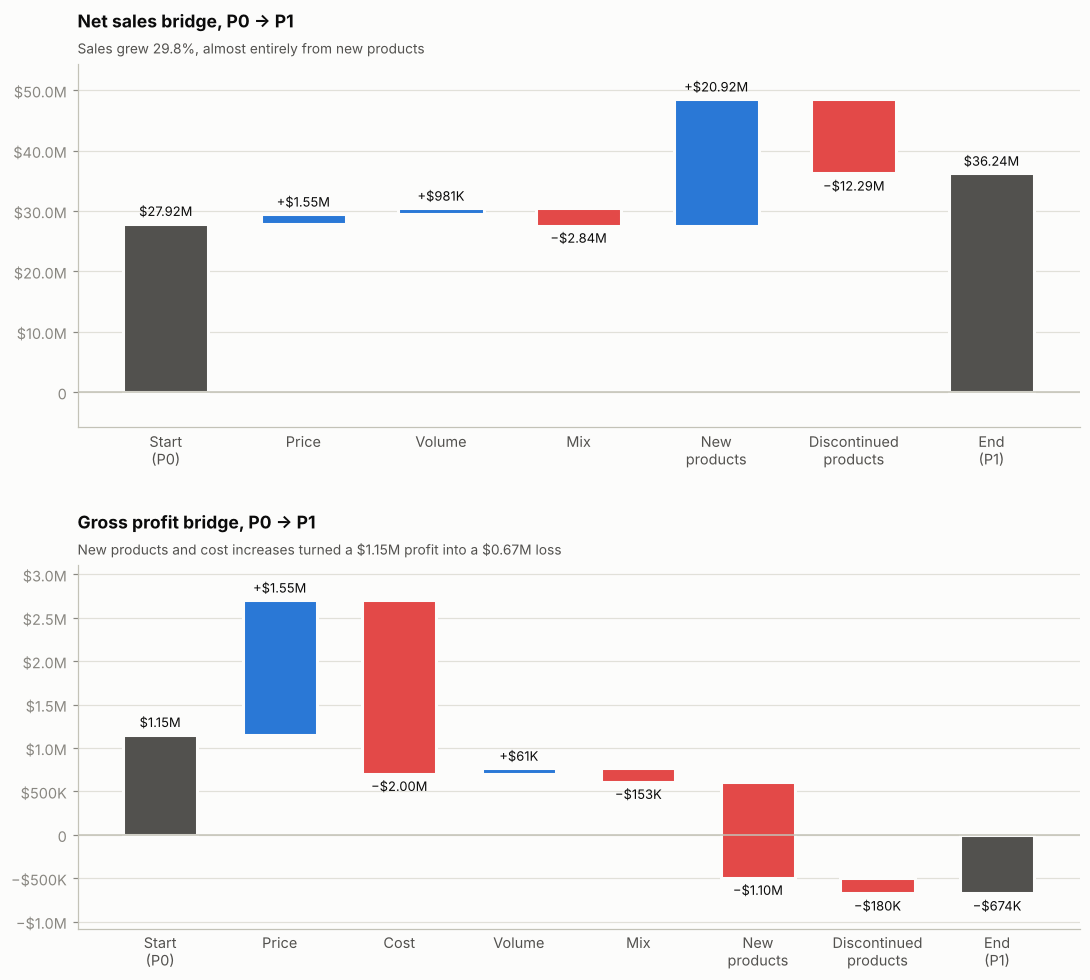

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9))
ch.bridge(bridge.net_sales.drop("Cost"), "Net sales bridge, P0 → P1",
          "Sales grew 29.8%, almost entirely from new products", ax=axes[0])
ch.bridge(bridge.gross_profit, "Gross profit bridge, P0 → P1",
          "New products and cost increases turned a $1.15M profit into a $0.67M loss", ax=axes[1])
fig.tight_layout(h_pad=3); fig.savefig(FIG / "fig03_pvm_bridges.png"); plt.show()
ch.bridge(bridge.gross_profit, "Gross profit bridge, P0 → P1")
plt.savefig(FIG / "fig03b_gp_bridge.png"); plt.close()

In [9]:
piv = df[df.period.notna()].pivot_table(index="sku", columns="period", values="qty", aggfunc="sum")
status = np.select([piv.P0.notna() & piv.P1.notna(), piv.P1.notna()], ["Continuing", "New in P1"], "Discontinued")
print(pd.Series(status).value_counts().to_string())
new_skus = piv.index[status == "New in P1"]
pdd.summarise(p1[p1.sku.isin(new_skus)], "model").sort_values("gross_profit").head(6)[["net_sales", "gross_profit", "gross_margin_pct"]]

New in P1       118
Discontinued     58
Continuing       49


,net_sales,gross_profit,gross_margin_pct
model,,,
Touring-1000,"6,723,794.29","-829,643.19",-12.34
Touring-3000,"2,046,508.26","-338,699.91",-16.55
Road-350-W,"3,665,932.31","-285,229.19",-7.78
Short-Sleeve Classic Jersey,"235,030.25","-75,847.41",-32.27
Touring-2000,"1,681,187.67","-69,251.89",-4.12
Road-750,"966,079.59","-64,525.56",-6.68


**Q2 answer.** Of the −$1.83M swing: new products −$1.10M (Touring launched at a loss), cost rising faster than price on continuing products −$0.45M (price +$1.55M vs cost −$2.00M), discontinued profitable lines −$0.18M, mix −$0.15M; volume added only +$0.06M. **Sales growth came from products that lose money.**

## Q3 · Where does the money leak?

,amount,per_100_of_list
List value,"62,253,591.49",100.00
Dealer discount,"-24,901,436.60",-40.00
Promo in unit price,"-782,985.57",-1.26
Line discount,"-328,684.65",-0.53
Standard cost,"-36,914,211.81",-59.30
Gross profit,"-673,727.11",-1.08


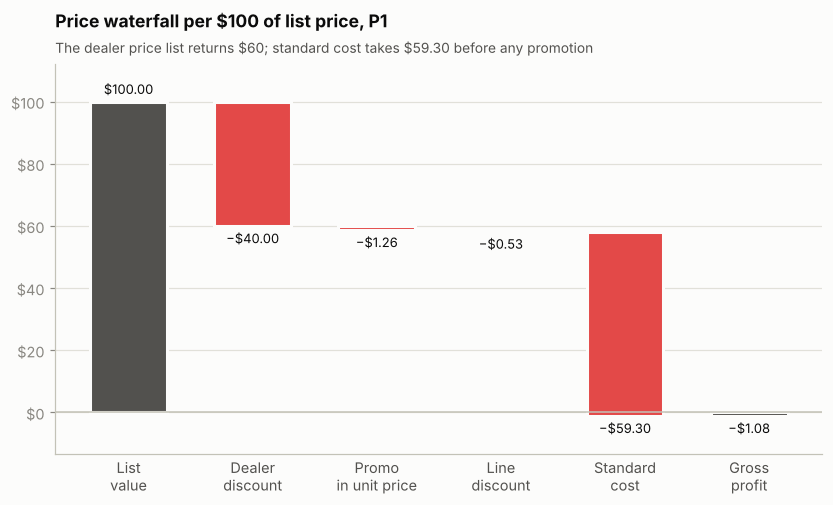

In [10]:
t = p1[["list_value", "dealer_value", "invoice_gross", "line_discount", "net_sales", "cogs", "gross_profit"]].sum()
waterfall = pd.Series({
    "List value": t.list_value,
    "Dealer discount": -(t.list_value - t.dealer_value),
    "Promo in unit price": -(t.dealer_value - t.invoice_gross),
    "Line discount": -t.line_discount,
    "Standard cost": -t.cogs,
    "Gross profit": t.gross_profit})
per100 = (waterfall / t.list_value * 100).rename("per_100_of_list")
display(pd.concat([waterfall.rename("amount"), per100], axis=1))
ch.bridge(per100.rename(lambda s: s.replace(" ", "\n", 1)), "Price waterfall per $100 of list price, P1",
          "The dealer price list returns $60; standard cost takes $59.30 before any promotion",
          fmt=lambda v: ("−" if v < 0 else "") + f"${abs(v):.2f}")
plt.gca().yaxis.set_major_formatter(lambda v, _: f"${v:.0f}")
plt.savefig(FIG / "fig04_price_waterfall.png"); plt.show()

In [11]:
rate = np.where(p1.invoice_gross > 0, p1.line_discount / p1.invoice_gross, np.nan)
band = pd.cut(rate, [-0.0001, 0, .10, .20, .30, 1], labels=["0%", "0–10%", "10–20%", "20–30%", "30%+"])
bands = pdd.summarise(p1.assign(band=band), "band")[["lines", "net_sales", "gross_profit", "gross_margin_pct"]]
display(bands[bands.lines > 0])
promo_loss = p1.loc[p1.discount_pct > 0, "gross_profit"].sum()
print(f"Promoted lines: {(p1.discount_pct > 0).mean():.1%} of lines, gross profit {promo_loss:,.0f}")

,lines,net_sales,gross_profit,gross_margin_pct
band,,,,
0%,28388,"32,645,904.78","393,166.59",1.20
0–10%,1349,"2,533,906.42","-150,304.04",-5.93
10–20%,820,"1,034,774.35","-824,749.57",-79.70
30%+,169,"25,899.14","-91,840.10",-354.61


Promoted lines: 7.6% of lines, gross profit -1,066,894


In [12]:
bc = df[df.period.notna()].groupby("period").apply(lambda g: pd.Series({
    "net_sales_below_cost": g.loc[g.is_priced_below_cost == 1, "net_sales"].sum(),
    "share_of_sales_pct": g.loc[g.is_priced_below_cost == 1, "net_sales"].sum() / g.net_sales.sum() * 100,
    "gp_below_cost_lines": g.loc[g.is_priced_below_cost == 1, "gross_profit"].sum(),
    "gp_other_lines": g.loc[g.is_priced_below_cost == 0, "gross_profit"].sum()}), include_groups=False)
bc

,net_sales_below_cost,share_of_sales_pct,gp_below_cost_lines,gp_other_lines
period,,,,
P0,"13,377,538.93",47.91,"-499,278.05","1,652,722.82"
P1,"21,930,915.52",60.51,"-2,042,236.65","1,368,509.53"


In [13]:
m = p1[p1.is_priced_below_cost == 1].groupby("model").agg(
    dealer_value=("dealer_value", "sum"), cost=("cogs", "sum"), gross_profit=("gross_profit", "sum"))
m["dealer_price_vs_cost_pct"] = (m.dealer_value - m.cost) / m.dealer_value * 100
m.sort_values("gross_profit")[["dealer_price_vs_cost_pct", "gross_profit"]]

,dealer_price_vs_cost_pct,gross_profit
model,,
Touring-1000,-3.60,"-829,643.19"
Touring-3000,-3.60,"-338,699.91"
Road-350-W,-6.07,"-285,229.19"
Road-250,-6.07,"-195,890.12"
Road-550-W,-6.07,"-113,194.94"
Short-Sleeve Classic Jersey,-28.33,"-75,847.41"
Touring-2000,-3.60,"-69,251.89"
Road-750,-6.07,"-64,525.56"
Long-Sleeve Logo Jersey,-28.33,"-48,221.73"


**Q3 answer.** 60.5% of P1 sales (up from 47.9% in P0) are products whose **dealer price is below standard cost** — they lose money before any discount. Promotions then make it worse: promoted lines (7.6% of lines) lose $1.07M, and on promoted lines the price is reduced twice (in the unit price and again as a line discount).

## Q4 · What should the client do? Scenarios on P1

,gross_profit,change_vs_actual
Actual,"-673,727.11",0.00
S4 Cap discounts at 15%,"-626,602.58","47,124.54"
S3 Apply promotions once,"-31,848.26","641,878.85"
"S2 Price floor, lose every affected order","491,988.38","1,165,715.50"
"S1 Price floor at cost, volume held","1,021,905.54","1,695,632.66"


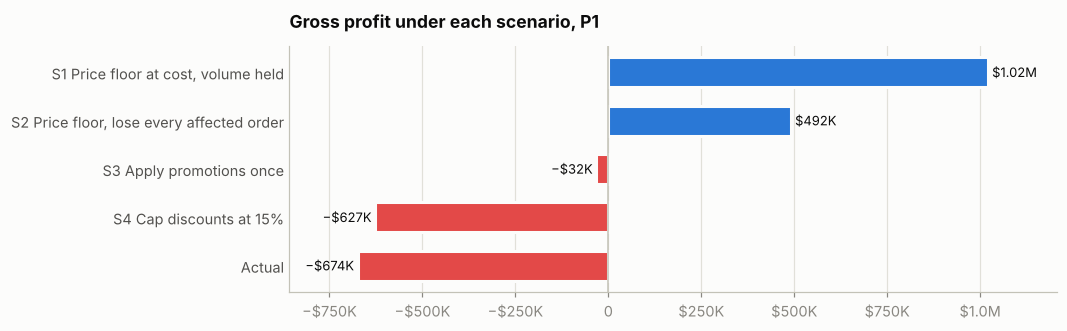

In [14]:
sc = pd.Series({
    "Actual": p1.gross_profit.sum(),
    "S4 Cap discounts at 15%": np.where(p1.discount_pct > .15, p1.invoice_gross * .85 - p1.cogs, p1.gross_profit).sum(),
    "S3 Apply promotions once": np.where(p1.discount_pct > 0, p1.dealer_value * (1 - p1.discount_pct) - p1.cogs,
                                         p1.gross_profit).sum(),
    "S2 Price floor, lose every affected order": p1.loc[~p1.order_number.isin(
        p1.loc[p1.is_priced_below_cost == 1, "order_number"]), "gross_profit"].sum(),
    "S1 Price floor at cost, volume held": (np.maximum(p1.unit_price, p1.unit_cost) * p1.qty
                                            * (1 - p1.discount_pct) - p1.cogs).sum(),
})
scen = pd.DataFrame({"gross_profit": sc, "change_vs_actual": sc - sc["Actual"]})
display(scen)
ch.hbar(sc, "Gross profit under each scenario, P1", sort=False)
plt.savefig(FIG / "fig05_scenarios.png"); plt.show()

In [15]:
orders = p1.groupby("order_number").apply(lambda g: pd.Series({
    "has_below_cost": g.is_priced_below_cost.max(),
    "gp_below_cost_lines": g.loc[g.is_priced_below_cost == 1, "gross_profit"].sum(),
    "gp_other_lines": g.loc[g.is_priced_below_cost == 0, "gross_profit"].sum()}), include_groups=False)
orders.groupby("has_below_cost").agg(orders=("gp_other_lines", "size"), gp_below_cost_lines=("gp_below_cost_lines", "sum"),
                                     gp_other_lines=("gp_other_lines", "sum"))

,orders,gp_below_cost_lines,gp_other_lines
has_below_cost,,,
0.00,510,0.00,"491,988.38"
1.00,1292,"-2,042,236.65","876,521.15"


**Why the worst case still gains (market-basket check).** Orders that contain a below-cost line also buy profitable items (+$0.88M), but the below-cost lines lose $2.04M. Even if repricing lost every one of those orders, gross profit would rise by $1.17M. The realistic result sits between **S2 (+$1.17M)** and **S1 (+$1.70M)**. Capping discounts alone (S4) is worth only $47K — the plan's original "cap discounts at 20%" idea would have missed the real problem.

## Findings summary

In [16]:
findings = pd.DataFrame([
    ["Sales +29.8% but gross profit fell from +$1.15M to −$0.67M", "Period totals", "−$1.83M", "Diagnose before growing volume further"],
    ["60.5% of sales are products with dealer price below standard cost", "Q3 · below-cost share", "−$2.04M on those lines",
     "Price floor: no dealer price below cost (Road +6.07%, Touring +3.60%, jerseys +28.33%)"],
    ["New products (Touring) launched at a loss", "Q2 · PVM new products", "−$1.10M", "Launch gate: margin check before listing"],
    ["Costs rose faster than prices on continuing products", "Q2 · price vs cost effect", "−$0.45M net", "Pass cost increases into the price list"],
    ["Promotions run on loss-making products and reduce price twice", "Q3 · discount bands, price build", "−$1.07M on promoted lines",
     "Stop promotions on below-cost SKUs; apply each promotion once (+$0.64M)"],
    ["Discount cap alone barely helps", "Q4 · S4", "+$0.05M", "Do not lead with a discount cap"],
], columns=["finding", "evidence", "impact", "action"])
findings.to_csv("../12_Business_Insights/findings.csv", index=False)
findings

,finding,evidence,impact,action
0,Sales +29.8% but gross profit fell from +$1.15...,Period totals,−$1.83M,Diagnose before growing volume further
1,60.5% of sales are products with dealer price ...,Q3 · below-cost share,−$2.04M on those lines,Price floor: no dealer price below cost (Road ...
2,New products (Touring) launched at a loss,Q2 · PVM new products,−$1.10M,Launch gate: margin check before listing
3,Costs rose faster than prices on continuing pr...,Q2 · price vs cost effect,−$0.45M net,Pass cost increases into the price list
4,Promotions run on loss-making products and red...,"Q3 · discount bands, price build",−$1.07M on promoted lines,Stop promotions on below-cost SKUs; apply each...
5,Discount cap alone barely helps,Q4 · S4,+$0.05M,Do not lead with a discount cap
